# HomeWise — Pelatihan Model Klasifikasi Kondisi Bangunan (CLAHE + MobileNetV2 + XGBoost)

Notebook ini mengunduh dan mengekstrak dataset publik **BD3 (Building Defects Detection Dataset)** secara otomatis dari internet, lalu melatih model hybrid:
1. **Preprocessing CLAHE** (pada kanal luminansi L ruang warna LAB) untuk mempertajam tekstur retakan dan noda.
2. **Ekstraksi Fitur CNN (MobileNetV2)** menghasilkan vektor `1.280` fitur dan diekspor ke format **ONNX** agar ringan di server produksi.
3. **Classifier Utama XGBoost** pada split stratified `80:20` untuk mengklasifikasikan 7 kelas kondisi permukaan (`algae`, `major_crack`, `minor_crack`, `peeling`, `plain`, `spalling`, `stain`).
4. **Integrasi HomeWise** (`prediksi.py`) yang memetakan prediksi visual + konteks area foto menjadi temuan dengan `jenis`, `tingkat`, `kepercayaan`, `luas_m2`, dan `kotak`.

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from PIL import Image

from latih import (
    DIR_ARTEFAK,
    DIR_DATASET,
    EkstraktorMobileNetV2,
    ekspor_onnx,
    ekstrak_fitur_cnn,
    hitung_spesifisitas_rata,
    muat_daftar_gambar,
    terapkan_clahe_rgb,
    unduh_dan_ekstrak_bd3,
)
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

DIR_ARTEFAK.mkdir(parents=True, exist_ok=True)
print('Direktori dataset:', DIR_DATASET)
print('Direktori artefak:', DIR_ARTEFAK)

Direktori dataset: /workspace/dataset
Direktori artefak: /workspace/artefak


## 1. Unduh & Ekstrak Dataset Publik BD3
Dataset diunduh otomatis dari Kaggle (`3.965` gambar RGB, `7` kelas).

In [2]:
dir_train = unduh_dan_ekstrak_bd3(DIR_DATASET)
jalur_gambar, y, kelas = muat_daftar_gambar(dir_train)

distribusi = Counter(kelas[idx] for idx in y)
print(f'Total gambar: {len(jalur_gambar)} | Jumlah kelas: {len(kelas)}')
for k, v in distribusi.items():
    print(f'  - {k:14s}: {v} gambar')

[Dataset] Mengunduh BD3 dari https://www.kaggle.com/api/v1/datasets/download/praveenkottari/bd3-dataset-for-building-defect-detection ...


Unduh BD3:   0%|          | 0.00/104M [00:00<?, ?B/s]

Unduh BD3:   0%|          | 262k/104M [00:00<03:08, 550kB/s]

Unduh BD3:   1%|          | 1.05M/104M [00:00<00:48, 2.12MB/s]

Unduh BD3:   2%|▏         | 1.84M/104M [00:00<00:34, 2.99MB/s]

Unduh BD3:   3%|▎         | 2.62M/104M [00:00<00:25, 3.94MB/s]

... (110 outputs left out)

Unduh BD3:  99%|█████████▉| 103M/104M [00:15<00:00, 7.41MB/s]

Unduh BD3: 100%|██████████| 104M/104M [00:15<00:00, 6.78MB/s]

[Dataset] Mengekstrak bd3_dataset.zip ...


Total gambar: 3965 | Jumlah kelas: 7
  - algae         : 620 gambar
  - major_crack   : 580 gambar
  - minor_crack   : 624 gambar
  - peeling       : 520 gambar
  - plain         : 600 gambar
  - spalling      : 500 gambar
  - stain         : 521 gambar


## 2. Visualisasi Sampel & Efek Preprocessing CLAHE

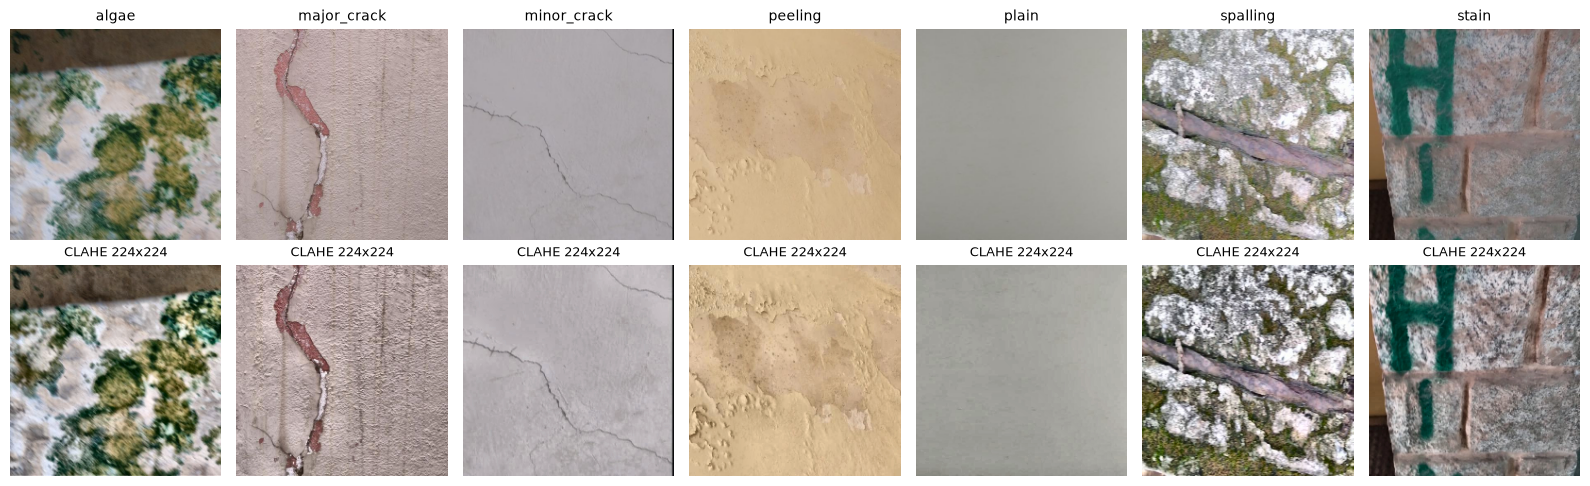

In [3]:
fig, axes = plt.subplots(2, len(kelas), figsize=(16, 5))
for col, nama_kelas in enumerate(kelas):
    idx_contoh = next(i for i, lbl in enumerate(y) if kelas[lbl] == nama_kelas)
    with Image.open(jalur_gambar[idx_contoh]) as im:
        rgb = np.array(im.convert('RGB'))
    clahe_rgb = terapkan_clahe_rgb(rgb, 224)
    axes[0, col].imshow(rgb)
    axes[0, col].set_title(nama_kelas, fontsize=10)
    axes[0, col].axis('off')
    axes[1, col].imshow(clahe_rgb)
    axes[1, col].set_title('CLAHE 224x224', fontsize=9)
    axes[1, col].axis('off')
plt.tight_layout()
plt.show()

## 3. Ekstraksi Fitur CNN (MobileNetV2) & Ekspor ONNX

In [4]:
ekstraktor = EkstraktorMobileNetV2()
jalur_onnx = DIR_ARTEFAK / 'mobilenetv2_fitur.onnx'
ekspor_onnx(ekstraktor, jalur_onnx)
print(f'Model ONNX tersimpan: {jalur_onnx} ({jalur_onnx.stat().st_size / 1e6:.2f} MB)')

X_fitur = ekstrak_fitur_cnn(jalur_gambar, ekstraktor, batch_size=32)
print('Bentuk matriks fitur:', X_fitur.shape)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


  0%|          | 0.00/13.6M [00:00<?, ?B/s]

  3%|▎         | 384k/13.6M [00:00<00:04, 3.31MB/s]

  8%|▊         | 1.12M/13.6M [00:00<00:02, 5.51MB/s]

 15%|█▍        | 2.00M/13.6M [00:00<00:01, 6.58MB/s]

 21%|██        | 2.88M/13.6M [00:00<00:01, 7.35MB/s]

... (138 outputs left out)

Ekstraksi MobileNetV2:  99%|█████████▉| 123/124 [01:48<00:00,  1.23it/s]

Ekstraksi MobileNetV2: 100%|██████████| 124/124 [01:49<00:00,  1.30it/s]

Ekstraksi MobileNetV2: 100%|██████████| 124/124 [01:49<00:00,  1.13it/s]

Bentuk matriks fitur: (3965, 1280)


## 4. Pelatihan Classifier XGBoost (Split 80:20) & Evaluasi

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X_fitur, y, test_size=0.20, stratify=y, random_state=42
)
clf = XGBClassifier(
    n_estimators=250,
    max_depth=5,
    learning_rate=0.08,
    subsample=0.85,
    colsample_bytree=0.85,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1,
)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
akurasi = float(accuracy_score(y_test, y_pred))
prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
cm = confusion_matrix(y_test, y_pred)
spesifisitas = hitung_spesifisitas_rata(cm)

print(f'Akurasi       : {akurasi * 100:.2f}%')
print(f'Sensitivitas  : {rec * 100:.2f}%')
print(f'Spesifisitas  : {spesifisitas * 100:.2f}%')
print(f'Macro F1      : {f1 * 100:.2f}%\n')
print(classification_report(y_test, y_pred, target_names=kelas, zero_division=0))

Akurasi       : 87.64%
Sensitivitas  : 87.52%
Spesifisitas  : 97.94%
Macro F1      : 87.57%

              precision    recall  f1-score   support

       algae       0.93      0.97      0.95       124
 major_crack       0.77      0.81      0.79       116
 minor_crack       0.83      0.81      0.82       125
     peeling       0.90      0.90      0.90       104
       plain       0.96      0.96      0.96       120
    spalling       0.92      0.88      0.90       100
       stain       0.83      0.80      0.81       104

    accuracy                           0.88       793
   macro avg       0.88      0.88      0.88       793
weighted avg       0.88      0.88      0.88       793



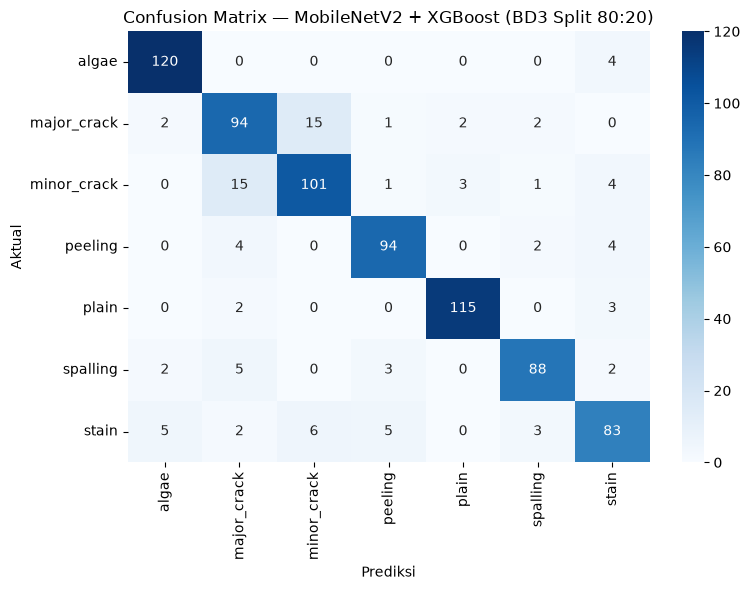

In [6]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=kelas, yticklabels=kelas)
plt.title('Confusion Matrix — MobileNetV2 + XGBoost (BD3 Split 80:20)')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.tight_layout()
plt.show()

## 5. Simpan Artefak Model & Uji Inferensi Kontrak HomeWise

In [7]:
jalur_xgb = DIR_ARTEFAK / 'model_xgboost.json'
clf.save_model(str(jalur_xgb))

laporan_kelas = classification_report(y_test, y_pred, target_names=kelas, output_dict=True, zero_division=0)
metadata = {
    'dataset': 'BD3 Building Defects Detection Dataset (3.965 gambar asli)',
    'ekstraktor': 'MobileNetV2 (ImageNet weights, 1280 fitur) + CLAHE LAB',
    'classifier': 'XGBoost (XGBClassifier)',
    'split': '80:20 stratified',
    'jumlah_latih': int(len(X_train)),
    'jumlah_uji': int(len(X_test)),
    'kelas': kelas,
    'metrik': {
        'akurasi': round(akurasi, 4),
        'precision_makro': round(float(prec), 4),
        'recall_sensitivitas_makro': round(float(rec), 4),
        'spesifisitas_makro': round(spesifisitas, 4),
        'f1_makro': round(float(f1), 4),
    },
    'laporan_per_kelas': laporan_kelas,
    'confusion_matrix': cm.tolist(),
}
(DIR_ARTEFAK / 'metadata_model.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
print('Artefak tersimpan di:', DIR_ARTEFAK)

# Uji inferensi langsung memakai modul produksi prediksi.py
import prediksi

contoh_uji = []
for idx_c, target_k in enumerate(['major_crack', 'peeling', 'stain', 'plain'], start=1):
    pos = next(i for i, lbl in enumerate(y) if kelas[lbl] == target_k)
    p = jalur_gambar[pos]
    contoh_uji.append({'id': idx_c, 'nama_berkas': p.name, 'area': 'dinding_bawah', '_path': p})

for c in contoh_uji:
    hasil = prediksi._analisis_satu_foto(c['_path'], c['id'], c['area'])
    print(f"Input ({c['_path'].parent.name}) -> {hasil}")

Artefak tersimpan di: /workspace/artefak


Input (major_crack) -> [{'jenis': 'cat_mengelupas', 'tingkat': 'ringan', 'kepercayaan': 0.74, 'luas_m2': 4.3, 'kotak': {'x': 0.2, 'y': 0.2, 'lebar': 0.6, 'tinggi': 0.6}, 'foto_id': 1}, {'jenis': 'retak_dinding', 'tingkat': 'berat', 'kepercayaan': 0.56, 'luas_m2': 12.0, 'kotak': {'x': 0.0, 'y': 0.0, 'lebar': 1.0, 'tinggi': 1.0}, 'foto_id': 1}, {'jenis': 'noda_lembap', 'tingkat': 'ringan', 'kepercayaan': 0.52, 'luas_m2': 4.0, 'kotak': {'x': 0.42, 'y': 0.42, 'lebar': 0.58, 'tinggi': 0.58}, 'foto_id': 1}]
Input (peeling) -> [{'jenis': 'cat_mengelupas', 'tingkat': 'sedang', 'kepercayaan': 0.92, 'luas_m2': 4.3, 'kotak': {'x': 0.2, 'y': 0.2, 'lebar': 0.6, 'tinggi': 0.6}, 'foto_id': 2}, {'jenis': 'noda_lembap', 'tingkat': 'sedang', 'kepercayaan': 0.79, 'luas_m2': 4.0, 'kotak': {'x': 0.0, 'y': 0.0, 'lebar': 0.58, 'tinggi': 0.58}, 'foto_id': 2}]
Input (stain) -> [{'jenis': 'cat_mengelupas', 'tingkat': 'berat', 'kepercayaan': 0.96, 'luas_m2': 4.0, 'kotak': {'x': 0.42, 'y': 0.42, 'lebar': 0.58, 't

Input (plain) -> []
